
# 05 — Model Comparison and Evaluation

## Project: Machine Learning-Based Air Quality Classification System

### Objective

The objective of this notebook is to develop, evaluate, and compare multiple machine learning classification algorithms for predicting Air Quality Index (AQI) categories using pollutant measurements.

The six target categories are:

- Good
- Satisfactory
- Moderate
- Poor
- Very Poor
- Severe

### Modelling Approach

The experiments will investigate the performance of:

1. Decision Tree Classifier
2. Random Forest Classifier
3. Extra Trees Classifier
4. Gradient Boosting Classifier

The models will be evaluated using accuracy, macro F1-score, weighted F1-score, and class-level precision and recall.

### Evaluation Strategy

A chronological train-validation-test split will be maintained to preserve the temporal ordering of observations and reduce information leakage.

Macro F1-score and per-class recall will receive particular attention because the dataset contains imbalanced AQI categories.

The goal is to identify a reliable classifier that performs reasonably across all six AQI categories, rather than optimizing accuracy alone.



## 1. Imports and Configuration

This section imports the libraries required for data preparation, preprocessing, model development, and evaluation.

A fixed random state will be used where applicable to support reproducibility.


In [1]:

import pandas as pd
import numpy as np

from pathlib import Path

from sklearn.impute import SimpleImputer

from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier
)

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix
)

from sklearn.utils.class_weight import compute_sample_weight

RANDOM_STATE = 42

pd.set_option("display.max_columns", None)



## 2. Dataset Loading and Preparation

The dataset used in this project is the City Hour dataset from Rohan Rao's Air Quality Data in India collection on Kaggle.

The target variable is `AQI_Bucket`, representing six air-quality categories.

The ten original pollutant features are retained:

- PM2.5
- PM10
- NO
- NO2
- NOx
- NH3
- CO
- SO2
- O3
- Benzene

The `AQI` numerical column is excluded because it is directly associated with the AQI category and could introduce target leakage.

Only observations with available target labels are retained for supervised learning.



### 2.1 Loading the Dataset

Load the original dataset and define the target variable and selected pollutant features.

The dataset path is relative to the notebooks directory.


In [2]:

# Load dataset

data_path = Path("../data/raw/city_hour.csv")

df = pd.read_csv(data_path)

df["Datetime"] = pd.to_datetime(df["Datetime"])

target = "AQI_Bucket"

features_10 = [
    "PM2.5",
    "PM10",
    "NO",
    "NO2",
    "NOx",
    "NH3",
    "CO",
    "SO2",
    "O3",
    "Benzene"
]

# Retain observations with available target labels

model_df = df.dropna(subset=[target]).copy()

print("Original dataset shape:", df.shape)
print("Labelled dataset shape:", model_df.shape)

print("\nTarget distribution:")
print(model_df[target].value_counts())


Original dataset shape: (707875, 16)
Labelled dataset shape: (578795, 16)

Target distribution:
AQI_Bucket
Moderate        198991
Satisfactory    189434
Poor             66654
Very Poor        57455
Good             38611
Severe           27650
Name: count, dtype: int64



### 2.2 Chronological Train-Validation-Test Split

The labelled observations are divided chronologically into three subsets:

- Training: 64% of labelled observations approximately.
- Validation: 16% approximately.
- Testing: 20% approximately.

The first 80% of unique timestamps form the development period. This development period is then divided into training and validation periods using an 80:20 chronological split.

This approach ensures that observations from later timestamps are not used to train models evaluated on earlier timestamps.

Unique timestamps are used as split boundaries to prevent observations from the same hour from crossing between subsets.


In [3]:

# Sort observations chronologically

model_df = model_df.sort_values("Datetime").reset_index(drop=True)

# Obtain unique timestamps

unique_dates = np.sort(model_df["Datetime"].unique())

# Development and test split

test_start_idx = int(len(unique_dates) * 0.80)
test_start_date = unique_dates[test_start_idx]

development_df = model_df[
    model_df["Datetime"] < test_start_date
].copy()

test_df = model_df[
    model_df["Datetime"] >= test_start_date
].copy()

# Training and validation split within development data

development_dates = np.sort(development_df["Datetime"].unique())

val_start_idx = int(len(development_dates) * 0.80)
val_start_date = development_dates[val_start_idx]

train_df = development_df[
    development_df["Datetime"] < val_start_date
].copy()

val_df = development_df[
    development_df["Datetime"] >= val_start_date
].copy()

# Separate features and target

X_train = train_df[features_10]
X_val = val_df[features_10]
X_test = test_df[features_10]

y_train = train_df[target]
y_val = val_df[target]
y_test = test_df[target]

# Display split information

print("Training observations:", len(X_train))
print("Validation observations:", len(X_val))
print("Testing observations:", len(X_test))

print("\nDate ranges:")
print("Training:", train_df["Datetime"].min(), "to", train_df["Datetime"].max())
print("Validation:", val_df["Datetime"].min(), "to", val_df["Datetime"].max())
print("Testing:", test_df["Datetime"].min(), "to", test_df["Datetime"].max())



Training observations: 242225
Validation observations: 130370
Testing observations: 206200

Date ranges:
Training: 2015-01-01 16:00:00 to 2018-07-09 07:00:00
Validation: 2018-07-09 08:00:00 to 2019-05-26 12:00:00
Testing: 2019-05-26 13:00:00 to 2020-07-01 00:00:00



### 2.3 Handling Missing Values

The selected pollutant features contain missing measurements.

Median imputation is applied to handle missing values while retaining observations that would otherwise be excluded through complete-case analysis.

The imputer is fitted exclusively on the training dataset and subsequently used to transform the training, validation, and test datasets.

This ensures that information from validation and test observations does not influence the imputation statistics.


In [4]:

# Initialize median imputer

imputer = SimpleImputer(strategy="median")

# Fit on training data only

X_train_imputed = imputer.fit_transform(X_train)

# Transform validation and test data

X_val_imputed = imputer.transform(X_val)
X_test_imputed = imputer.transform(X_test)

print("Training shape:", X_train_imputed.shape)
print("Validation shape:", X_val_imputed.shape)
print("Testing shape:", X_test_imputed.shape)

print("\nMissing values after imputation:")
print("Training:", np.isnan(X_train_imputed).sum())
print("Validation:", np.isnan(X_val_imputed).sum())
print("Testing:", np.isnan(X_test_imputed).sum())


Training shape: (242225, 10)
Validation shape: (130370, 10)
Testing shape: (206200, 10)

Missing values after imputation:
Training: 0
Validation: 0
Testing: 0



## 3. Baseline Model: Decision Tree Classifier

A Decision Tree Classifier is used as the initial machine learning baseline.

The model uses a maximum tree depth of 5 and a fixed random state of 42.

This baseline provides a reference point for evaluating whether more advanced ensemble algorithms improve classification performance.

The model is trained on the imputed training dataset and evaluated on the chronological validation dataset.

Evaluation metrics include accuracy, macro F1-score, weighted F1-score, and class-level precision and recall.


In [6]:

# Train Decision Tree baseline

baseline_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=RANDOM_STATE
)

baseline_model.fit(X_train_imputed, y_train)

# Generate validation predictions

y_val_pred_baseline = baseline_model.predict(X_val_imputed)

# Evaluate baseline

print("Decision Tree Baseline Results")
print("------------------------------")

print("Accuracy:",
      round(accuracy_score(y_val, y_val_pred_baseline), 4))

print("Macro F1:",
      round(f1_score(y_val, y_val_pred_baseline, average="macro"), 4))

print("Weighted F1:",
      round(f1_score(y_val, y_val_pred_baseline, average="weighted"), 4))

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_pred_baseline,
    zero_division=0
))


Decision Tree Baseline Results
------------------------------
Accuracy: 0.593
Macro F1: 0.4439
Weighted F1: 0.5695

Classification Report:
              precision    recall  f1-score   support

        Good       0.00      0.00      0.00      4378
    Moderate       0.60      0.72      0.65     49578
        Poor       0.37      0.19      0.25     16502
Satisfactory       0.66      0.70      0.68     38766
      Severe       0.69      0.46      0.55      7820
   Very Poor       0.49      0.57      0.52     13326

    accuracy                           0.59    130370
   macro avg       0.47      0.44      0.44    130370
weighted avg       0.56      0.59      0.57    130370




### 4.1 Tuned Random Forest

The selected configuration uses:

- 200 decision trees
- Maximum depth of 15
- Minimum samples per leaf of 5
- Minimum samples required to split a node of 20
- Balanced class weights

The model is trained on the imputed training dataset and evaluated on the validation dataset.


In [7]:

# Train tuned Random Forest

rf_split_controlled = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=5,
    min_samples_split=20,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    class_weight="balanced"
)

rf_split_controlled.fit(X_train_imputed, y_train)

# Validation predictions

y_val_pred_split = rf_split_controlled.predict(X_val_imputed)

# Evaluation

print("Tuned Random Forest Results")
print("---------------------------")

print("Accuracy:",
      round(accuracy_score(y_val, y_val_pred_split), 4))

print("Macro F1:",
      round(f1_score(y_val, y_val_pred_split, average="macro"), 4))

print("Weighted F1:",
      round(f1_score(y_val, y_val_pred_split, average="weighted"), 4))

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_pred_split,
    zero_division=0
))


Tuned Random Forest Results
---------------------------
Accuracy: 0.6036
Macro F1: 0.5499
Weighted F1: 0.6064

Classification Report:
              precision    recall  f1-score   support

        Good       0.39      0.62      0.48      4378
    Moderate       0.67      0.63      0.65     49578
        Poor       0.38      0.42      0.40     16502
Satisfactory       0.70      0.69      0.70     38766
      Severe       0.55      0.60      0.57      7820
   Very Poor       0.53      0.48      0.51     13326

    accuracy                           0.60    130370
   macro avg       0.54      0.57      0.55    130370
weighted avg       0.61      0.60      0.61    130370



## 5. Extra Trees Classifier

Extra Trees is an ensemble algorithm that builds randomized decision trees. We evaluate it using the same data split and class-weighting strategy as Random Forest.

In [8]:
# Train Extra Trees

extra_trees_model = ExtraTreesClassifier(
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=5,
    min_samples_split=20,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

extra_trees_model.fit(X_train_imputed, y_train)

# Validation predictions

y_val_pred_extra = extra_trees_model.predict(X_val_imputed)

# Evaluation

print("Extra Trees Results")
print("-------------------")

print("Accuracy:",
      round(accuracy_score(y_val, y_val_pred_extra), 4))

print("Macro F1:",
      round(f1_score(y_val, y_val_pred_extra, average="macro"), 4))

print("Weighted F1:",
      round(f1_score(y_val, y_val_pred_extra, average="weighted"), 4))

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_pred_extra,
    zero_division=0
))

Extra Trees Results
-------------------
Accuracy: 0.5524
Macro F1: 0.5153
Weighted F1: 0.5618

Classification Report:
              precision    recall  f1-score   support

        Good       0.25      0.80      0.38      4378
    Moderate       0.65      0.59      0.62     49578
        Poor       0.36      0.39      0.37     16502
Satisfactory       0.66      0.56      0.60     38766
      Severe       0.62      0.64      0.63      7820
   Very Poor       0.50      0.48      0.49     13326

    accuracy                           0.55    130370
   macro avg       0.50      0.58      0.52    130370
weighted avg       0.59      0.55      0.56    130370



## 6. Gradient Boosting Classifier

In [9]:
# Calculate balanced sample weights
sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

# Train Gradient Boosting

gb_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=RANDOM_STATE,
    subsample=0.8
)

gb_model.fit(
    X_train_imputed,
    y_train,
    sample_weight=sample_weights
)

# Validation predictions

y_val_pred_gb = gb_model.predict(X_val_imputed)

# Evaluation

print("Gradient Boosting Results")
print("-------------------------")

print("Accuracy:",
      round(accuracy_score(y_val, y_val_pred_gb), 4))

print("Macro F1:",
      round(f1_score(y_val, y_val_pred_gb, average="macro"), 4))

print("Weighted F1:",
      round(f1_score(y_val, y_val_pred_gb, average="weighted"), 4))

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_pred_gb,
    zero_division=0
))

Gradient Boosting Results
-------------------------
Accuracy: 0.5896
Macro F1: 0.5489
Weighted F1: 0.5952

Classification Report:
              precision    recall  f1-score   support

        Good       0.35      0.79      0.48      4378
    Moderate       0.68      0.59      0.63     49578
        Poor       0.36      0.44      0.40     16502
Satisfactory       0.69      0.67      0.68     38766
      Severe       0.61      0.64      0.63      7820
   Very Poor       0.51      0.45      0.48     13326

    accuracy                           0.59    130370
   macro avg       0.53      0.60      0.55    130370
weighted avg       0.61      0.59      0.60    130370



## 7. Comparative Model Evaluation
Compare all four models using accuracy, macro F1, weighted F1, and per-class recall on the same validation set.

In [10]:
# Collect validation predictions

predictions = {
    "Decision Tree": y_val_pred_baseline,
    "Random Forest": y_val_pred_split,
    "Extra Trees": y_val_pred_extra,
    "Gradient Boosting": y_val_pred_gb
}

# Overall metrics

comparison_results = []

for model_name, y_pred in predictions.items():
    comparison_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Macro F1": f1_score(y_val, y_pred, average="macro"),
        "Weighted F1": f1_score(y_val, y_pred, average="weighted")
    })

comparison_df = pd.DataFrame(comparison_results)

print("Overall Model Comparison")
display(comparison_df.round(4))

# Per-class recall

class_order = [
    "Good", "Satisfactory", "Moderate",
    "Poor", "Very Poor", "Severe"
]

recall_results = {}

for model_name, y_pred in predictions.items():
    recall_results[model_name] = recall_score(
        y_val,
        y_pred,
        labels=class_order,
        average=None,
        zero_division=0
    )

recall_df = pd.DataFrame(
    recall_results,
    index=class_order
)

recall_df.index.name = "AQI Category"

print("\nPer-Class Recall Comparison")
display(recall_df.round(4))

Overall Model Comparison


,Model,Accuracy,Macro F1,Weighted F1
0,Decision Tree,0.5930,0.4439,0.5695
1,Random Forest,0.6036,0.5499,0.6064
2,Extra Trees,0.5524,0.5153,0.5618
3,Gradient Boosting,0.5896,0.5489,0.5952



Per-Class Recall Comparison


,Decision Tree,Random Forest,Extra Trees,Gradient Boosting
AQI Category,,,,
Good,0.0000,0.6181,0.8013,0.7878
Satisfactory,0.6986,0.6943,0.5552,0.6734
Moderate,0.7248,0.6257,0.5878,0.5863
Poor,0.1917,0.4198,0.3863,0.4399
Very Poor,0.5664,0.4842,0.4832,0.4477
Severe,0.4586,0.5969,0.6428,0.6412


## 8. Model Performance Visualization

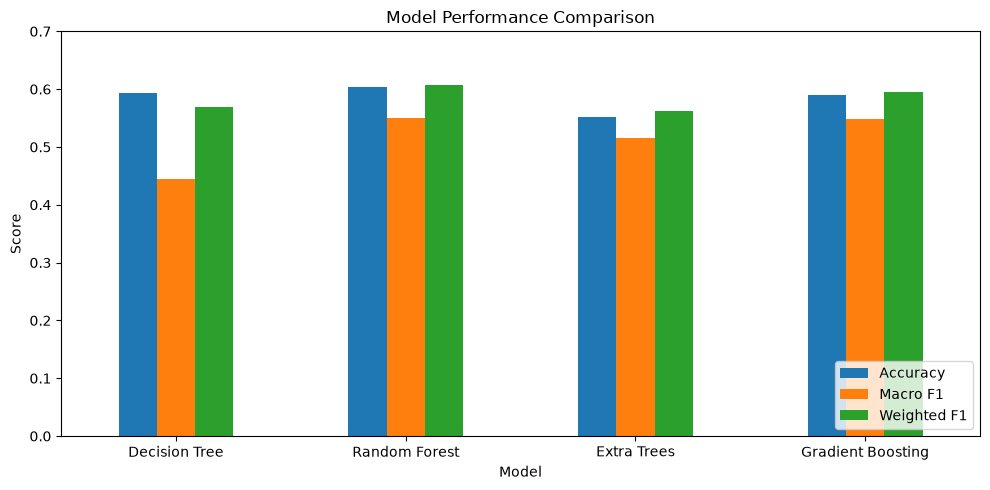

In [11]:
import matplotlib.pyplot as plt

comparison_df.set_index("Model")[
    ["Accuracy", "Macro F1", "Weighted F1"]
].plot(
    kind="bar",
    figsize=(10, 5),
    ylim=(0, 0.7)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 9. Generalization Analysis
Compare training and validation performance for Random Forest and Gradient Boosting to assess overfitting.

In [12]:
models_to_check = {
    "Random Forest": (rf_split_controlled, y_val_pred_split),
    "Gradient Boosting": (gb_model, y_val_pred_gb)
}

generalization_results = []

for name, (model, val_pred) in models_to_check.items():
    train_pred = model.predict(X_train_imputed)

    generalization_results.append({
        "Model": name,
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Validation Accuracy": accuracy_score(y_val, val_pred),
        "Train Macro F1": f1_score(y_train, train_pred, average="macro"),
        "Validation Macro F1": f1_score(y_val, val_pred, average="macro")
    })

generalization_df = pd.DataFrame(generalization_results)

display(generalization_df.round(4))

,Model,Train Accuracy,Validation Accuracy,Train Macro F1,Validation Macro F1
0,Random Forest,0.6911,0.6036,0.6736,0.5499
1,Gradient Boosting,0.5745,0.5896,0.5577,0.5489


## 10. Confusion Matrix Analysis
Confusion matrices are used to examine classification errors made by Random Forest and Gradient Boosting across the six AQI categories.

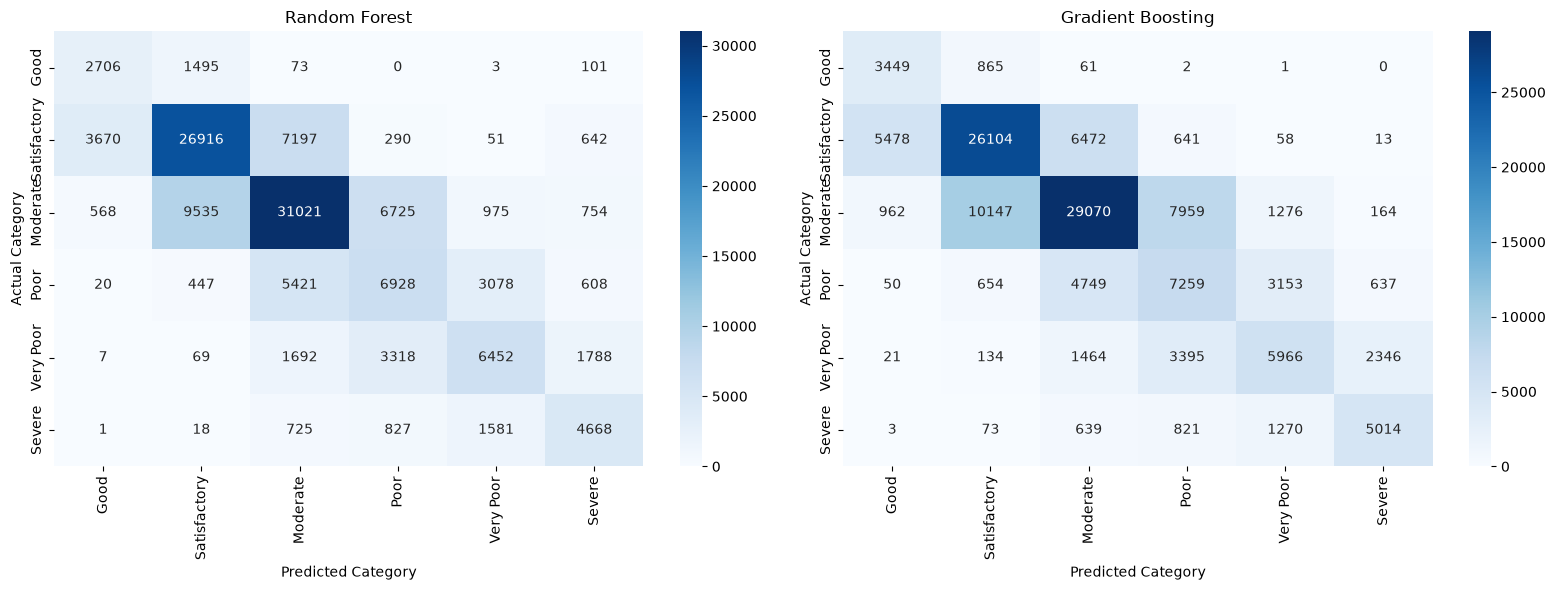

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

class_order = [
    "Good", "Satisfactory", "Moderate",
    "Poor", "Very Poor", "Severe"
]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, (name, y_pred) in zip(
    axes,
    [
        ("Random Forest", y_val_pred_split),
        ("Gradient Boosting", y_val_pred_gb)
    ]
):
    cm = confusion_matrix(y_val, y_pred, labels=class_order)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_order,
        yticklabels=class_order,
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Category")
    ax.set_ylabel("Actual Category")

plt.tight_layout()
plt.show()

## 11. Severity of Classification Errors
Measure classification error distance using the natural ordering of AQI categories.

In [14]:
class_order = [
    "Good", "Satisfactory", "Moderate",
    "Poor", "Very Poor", "Severe"
]

class_to_rank = {
    category: rank
    for rank, category in enumerate(class_order)
}

actual_ranks = y_val.map(class_to_rank).to_numpy()

for name, predictions_array in {
    "Random Forest": y_val_pred_split,
    "Gradient Boosting": y_val_pred_gb
}.items():

    predicted_ranks = pd.Series(predictions_array).map(
        class_to_rank
    ).to_numpy()

    error_distance = np.abs(actual_ranks - predicted_ranks)

    print(f"\n{name}")
    print("----------------------")
    print("Correct:",
          np.sum(error_distance == 0))
    print("One-category errors:",
          np.sum(error_distance == 1))
    print("Two-or-more-category errors:",
          np.sum(error_distance >= 2))
    print("Total errors:",
          np.sum(error_distance > 0))
    print("Percentage of errors two or more categories away:",
          round(
              np.mean(error_distance[error_distance > 0] >= 2) * 100,
              2
          ), "%")


Random Forest
----------------------
Correct: 78691
One-category errors: 43808
Two-or-more-category errors: 7871
Total errors: 51679
Percentage of errors two or more categories away: 15.23 %

Gradient Boosting
----------------------
Correct: 76862
One-category errors: 45834
Two-or-more-category errors: 7674
Total errors: 53508
Percentage of errors two or more categories away: 14.34 %


## 12. Random Forest Hyperparameter Optimization
Evaluate alternative Random Forest configurations to improve validation macro F1 while controlling overfitting.


### 12.1 Effect of Maximum Tree Depth

In [15]:
depth_results = []

for depth in [10, 15, 20]:

    model = RandomForestClassifier(
        n_estimators=200,
        max_depth=depth,
        min_samples_leaf=5,
        min_samples_split=20,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    model.fit(X_train_imputed, y_train)

    train_pred = model.predict(X_train_imputed)
    val_pred = model.predict(X_val_imputed)

    depth_results.append({
        "Max Depth": depth,
        "Train Macro F1": f1_score(
            y_train, train_pred, average="macro"
        ),
        "Validation Macro F1": f1_score(
            y_val, val_pred, average="macro"
        ),
        "Validation Accuracy": accuracy_score(
            y_val, val_pred
        ),
        "Validation Weighted F1": f1_score(
            y_val, val_pred, average="weighted"
        )
    })

depth_results_df = pd.DataFrame(depth_results)

display(depth_results_df.round(4))

,Max Depth,Train Macro F1,Validation Macro F1,Validation Accuracy,Validation Weighted F1
0,10,0.5807,0.5546,0.5946,0.5990
1,15,0.6736,0.5499,0.6036,0.6064
2,20,0.7486,0.5492,0.6072,0.6089


### 12.2 Effect of Minimum Samples per Leaf
Evaluate different minimum leaf sizes while keeping the remaining Random Forest parameters fixed.

In [16]:
leaf_results = []

for leaf_size in [3, 5, 10]:

    model = RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        min_samples_leaf=leaf_size,
        min_samples_split=20,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    model.fit(X_train_imputed, y_train)

    train_pred = model.predict(X_train_imputed)
    val_pred = model.predict(X_val_imputed)

    leaf_results.append({
        "Min Samples Leaf": leaf_size,
        "Train Macro F1": f1_score(
            y_train, train_pred, average="macro"
        ),
        "Validation Macro F1": f1_score(
            y_val, val_pred, average="macro"
        ),
        "Validation Accuracy": accuracy_score(
            y_val, val_pred
        ),
        "Validation Weighted F1": f1_score(
            y_val, val_pred, average="weighted"
        )
    })

leaf_results_df = pd.DataFrame(leaf_results)

display(leaf_results_df.round(4))

,Min Samples Leaf,Train Macro F1,Validation Macro F1,Validation Accuracy,Validation Weighted F1
0,3,0.5810,0.5544,0.5935,0.5982
1,5,0.5807,0.5546,0.5946,0.5990
2,10,0.5795,0.5546,0.5940,0.5984


### 12.3 Effect of Minimum Samples per Split
Evaluate different split thresholds while keeping the other Random Forest parameters constant.

In [17]:
split_results = []

for split_size in [10, 20, 40]:

    model = RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        min_samples_leaf=5,
        min_samples_split=split_size,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    model.fit(X_train_imputed, y_train)

    train_pred = model.predict(X_train_imputed)
    val_pred = model.predict(X_val_imputed)

    split_results.append({
        "Min Samples Split": split_size,
        "Train Macro F1": f1_score(
            y_train, train_pred, average="macro"
        ),
        "Validation Macro F1": f1_score(
            y_val, val_pred, average="macro"
        ),
        "Validation Accuracy": accuracy_score(
            y_val, val_pred
        ),
        "Validation Weighted F1": f1_score(
            y_val, val_pred, average="weighted"
        )
    })

split_results_df = pd.DataFrame(split_results)

display(split_results_df.round(4))

,Min Samples Split,Train Macro F1,Validation Macro F1,Validation Accuracy,Validation Weighted F1
0,10,0.5813,0.5556,0.5953,0.5998
1,20,0.5807,0.5546,0.5946,0.5990
2,40,0.5786,0.5536,0.5926,0.5971


### 12.4 Effect of Maximum Features
Compare square-root and logarithmic feature selection at each split to assess their effect on model performance.


In [18]:
feature_results = []

for max_feat in ["sqrt", "log2"]:

    model = RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        min_samples_leaf=5,
        min_samples_split=10,
        max_features=max_feat,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    model.fit(X_train_imputed, y_train)

    train_pred = model.predict(X_train_imputed)
    val_pred = model.predict(X_val_imputed)

    feature_results.append({
        "Max Features": max_feat,
        "Train Macro F1": f1_score(
            y_train, train_pred, average="macro"
        ),
        "Validation Macro F1": f1_score(
            y_val, val_pred, average="macro"
        ),
        "Validation Accuracy": accuracy_score(
            y_val, val_pred
        ),
        "Validation Weighted F1": f1_score(
            y_val, val_pred, average="weighted"
        )
    })

feature_results_df = pd.DataFrame(feature_results)

display(feature_results_df.round(4))

,Max Features,Train Macro F1,Validation Macro F1,Validation Accuracy,Validation Weighted F1
0,sqrt,0.5813,0.5556,0.5953,0.5998
1,log2,0.5813,0.5556,0.5953,0.5998


### 12.5 Comparison of Tuned Models
Compare the new Random Forest configuration with the previous Random Forest and Gradient Boosting models using identical training and validation data.

In [19]:
models = {
    "Previous Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=15,
        min_samples_leaf=5,
        min_samples_split=20,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "Tuned Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        min_samples_leaf=5,
        min_samples_split=10,
        max_features="sqrt",
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=RANDOM_STATE,
        subsample=0.8
    )
}

comparison_results = []
recall_results = []

for name, model in models.items():

    if name == "Gradient Boosting":
        sample_weights = compute_sample_weight(
            class_weight="balanced",
            y=y_train
        )
        model.fit(
            X_train_imputed,
            y_train,
            sample_weight=sample_weights
        )
    else:
        model.fit(X_train_imputed, y_train)

    predictions = model.predict(X_val_imputed)

    comparison_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Macro F1": f1_score(
            y_val, predictions, average="macro"
        ),
        "Weighted F1": f1_score(
            y_val, predictions, average="weighted"
        )
    })

    class_recalls = recall_score(
        y_val,
        predictions,
        labels=class_order,
        average=None,
        zero_division=0
    )

    recall_results.append({
        "Model": name,
        **dict(zip(class_order, class_recalls))
    })

comparison_df = pd.DataFrame(comparison_results)
recall_df = pd.DataFrame(recall_results)

print("Aggregate Performance")
display(comparison_df.round(4))

print("Per-Class Recall")
display(recall_df.round(4))

Aggregate Performance


,Model,Accuracy,Macro F1,Weighted F1
0,Previous Random Forest,0.6036,0.5499,0.6064
1,Tuned Random Forest,0.5953,0.5556,0.5998
2,Gradient Boosting,0.5896,0.5489,0.5952


Per-Class Recall


,Model,Good,Satisfactory,Moderate,Poor,Very Poor,Severe
0,Previous Random Forest,0.6181,0.6943,0.6257,0.4198,0.4842,0.5969
1,Tuned Random Forest,0.7579,0.6648,0.6097,0.4158,0.4835,0.6372
2,Gradient Boosting,0.7878,0.6734,0.5863,0.4399,0.4477,0.6412
